<a href="https://colab.research.google.com/github/YiruiLi2004/MSSP6070/blob/main/Assignments/Assignment%202/Assignment_2_Internet_Sales_Analysis_yiruili.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: Adventure Works Internet Sales Analysis

This notebook analyzes the Internet Sales dataset for Adventure Works Bicycle Company. The analysis focuses on sales trends, customer characteristics, product categories, homeownership, and additional patterns that may help leadership develop a strategy for growing Internet sales.

The workflow follows the course approach: inspect and clean the data, summarize important variables, aggregate with pandas, use dates for yearly analysis, visualize patterns, and then interpret the results.

## 1. Setup and Load the Data

The notebook clones the public `MSSP6070` GitHub repository and loads the Internet Sales CSV directly from the repository's `data` folder. This allows the notebook to run in a fresh Google Colab session without Google Drive or manual file uploads.

In [38]:
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

repo_url = "https://github.com/YiruiLi2004/MSSP6070.git"
repo_path = "/content/MSSP6070"

if not os.path.exists(repo_path):
    subprocess.run(["git", "clone", repo_url], check=True)

os.chdir(repo_path)
print(os.getcwd())

df = pd.read_csv("data/InternetSales.csv", encoding="latin1", low_memory=False)
df.head()

/content/MSSP6070


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


## 2. Data Preparation and Quality Check

Before analyzing sales, the dataset is checked for its shape, data types, missing values, duplicate rows, and the variables needed for the case study. Missing values in fields that are not used in the analysis are not automatically removed or filled.

In [39]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (60398, 60)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 60 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        60398 non-null  int64  
 1   CustomerKey               60398 non-null  int64  
 2   GeographyKey              60398 non-null  int64  
 3   City                      60398 non-null  object 
 4   CountryRegionCode         60398 non-null  object 
 5   EnglishCountryRegionName  60398 non-null  object 
 6   CustomerAlternateKey      60398 non-null  object 
 7   Title                     307 non-null    object 
 8   FirstName                 60398 non-null  object 
 9   MiddleName                34903 non-null  object 
 10  LastName                  60398 non-null  object 
 11  NameStyle                 60398 non-null  bool   
 12  BirthDate                 60398 non-null  object 
 13  MaritalStatus             60398 no

In [40]:
# Check duplicate rows and duplicate IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

# Show columns containing missing values
missing_values = df.isna().sum().sort_values(ascending=False)
missing_values = missing_values[missing_values > 0]
print()
print("Columns with missing values:")
display(missing_values.to_frame("Missing Values"))

Duplicate rows: 0
Duplicate IDs: 0

Columns with missing values:


,Missing Values
CustomerPONumber,60398
CarrierTrackingNumber,60398
Suffix,60392
Title,60091
AddressLine2,59293
MiddleName,25495


In [41]:
# Remove columns that are completely empty
all_missing_columns = df.columns[df.isna().all()].tolist()
print("Completely empty columns:", all_missing_columns)

df = df.drop(columns=all_missing_columns)
print("Shape after removing completely empty columns:", df.shape)

Completely empty columns: ['CarrierTrackingNumber', 'CustomerPONumber']
Shape after removing completely empty columns: (60398, 58)


In [42]:
# Check whether the duplicated customer key column contains the same values
print("CustomerKey and CustomerKey.1 are identical:",
      (df["CustomerKey"] == df["CustomerKey.1"]).all())

CustomerKey and CustomerKey.1 are identical: True


In [43]:
# Remove the duplicated customer identifier
df = df.drop(columns=["CustomerKey.1"])
print("Shape after removing duplicate customer key:", df.shape)

Shape after removing duplicate customer key: (60398, 57)


In [44]:
# Check the variables used in the main analysis
key_columns = [
    "CustomerKey", "EnglishCountryRegionName", "Gender", "YearlyIncome",
    "HouseOwnerFlag", "ProductKey", "EnglishProductName", "SalesOrderNumber",
    "OrderQuantity", "UnitPrice", "SalesAmount", "OrderDate"
]

key_missing = df[key_columns].isna().sum()
print("Missing values in key analysis variables:")
display(key_missing.to_frame("Missing Values"))

Missing values in key analysis variables:


,Missing Values
CustomerKey,0
EnglishCountryRegionName,0
Gender,0
YearlyIncome,0
HouseOwnerFlag,0
ProductKey,0
EnglishProductName,0
SalesOrderNumber,0
OrderQuantity,0
UnitPrice,0


In [45]:
# Convert the order date to datetime and create a year variable
df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df["OrderYear"] = df["OrderDate"].dt.year

# Create a readable homeownership label
df["HomeOwnership"] = df["HouseOwnerFlag"].map({1: "Homeowner", 0: "Non-homeowner"})

print("Order date range:", df["OrderDate"].min(), "to", df["OrderDate"].max())
print("Years in the dataset:", sorted(df["OrderYear"].unique()))

Order date range: 2010-12-29 00:00:00 to 2014-01-28 00:00:00
Years in the dataset: [np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]


In [46]:
# Check the amount of data available in each year
# 2010 and 2014 are partial years, while 2011-2013 cover full calendar years.
year_coverage = df.groupby("OrderYear")["OrderDate"].agg(["min", "max", "count"])
year_coverage.columns = ["First Order Date", "Last Order Date", "Sales Rows"]
display(year_coverage)

,First Order Date,Last Order Date,Sales Rows
OrderYear,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


In [47]:
# Check several fields that affect how sales should be interpreted
print("OrderQuantity values:")
print(df["OrderQuantity"].value_counts().sort_index())

print("UnitPriceDiscountPct values:")
print(df["UnitPriceDiscountPct"].value_counts().sort_index())

print("DiscountAmount values:")
print(df["DiscountAmount"].value_counts().sort_index())

print("SalesAmount equals UnitPrice for every row:",
    (df["SalesAmount"] == df["UnitPrice"]).all())

OrderQuantity values:
OrderQuantity
1    60398
Name: count, dtype: int64
UnitPriceDiscountPct values:
UnitPriceDiscountPct
0    60398
Name: count, dtype: int64
DiscountAmount values:
DiscountAmount
0    60398
Name: count, dtype: int64
SalesAmount equals UnitPrice for every row: True


- The dataset contains transaction-level sales records, so the same customer can appear in multiple rows.
- `OrderDate` is converted to a pandas datetime object so yearly sales can be analyzed.
- 2010 and 2014 are partial years and should not be interpreted as directly comparable with the full years 2011-2013.
- `OrderQuantity` is 1 for every row, and the discount fields are 0 throughout the dataset. Therefore, discount analysis is not useful for this case study.
- Customer-level variables such as gender, income, and homeownership are summarized using one record per customer when appropriate, so repeat purchasers do not receive extra weight in customer-profile statistics.

## 3. Overall Descriptive Summary

This section establishes the overall scale of the Internet business before making comparisons.

In [48]:
# Overall sales summary and descriptive statistics
sales_summary = pd.DataFrame({
    "Metric": [
        "Sales rows",
        "Unique customers",
        "Unique sales orders",
        "Total Internet sales",
        "Mean sales amount",
        "Median sales amount",
        "Standard deviation",
        "Minimum sales amount",
        "Maximum sales amount",
        "First quartile (Q1)",
        "Third quartile (Q3)",
        "Interquartile range (IQR)",
        "Skewness"
    ],
    "Value": [
        len(df),
        df["CustomerKey"].nunique(),
        df["SalesOrderNumber"].nunique(),
        df["SalesAmount"].sum(),
        df["SalesAmount"].mean(),
        df["SalesAmount"].median(),
        df["SalesAmount"].std(),
        df["SalesAmount"].min(),
        df["SalesAmount"].max(),
        df["SalesAmount"].quantile(0.25),
        df["SalesAmount"].quantile(0.75),
        df["SalesAmount"].quantile(0.75) - df["SalesAmount"].quantile(0.25),
        df["SalesAmount"].skew()
    ]
})

sales_summary["Value"] = sales_summary["Value"].round(2)

sales_summary

,Metric,Value
0,Sales rows,60398.00
1,Unique customers,18484.00
2,Unique sales orders,27659.00
3,Total Internet sales,29358677.22
4,Mean sales amount,486.09
5,Median sales amount,29.99
6,Standard deviation,928.49
7,Minimum sales amount,2.29
8,Maximum sales amount,3578.27
9,First quartile (Q1),7.95


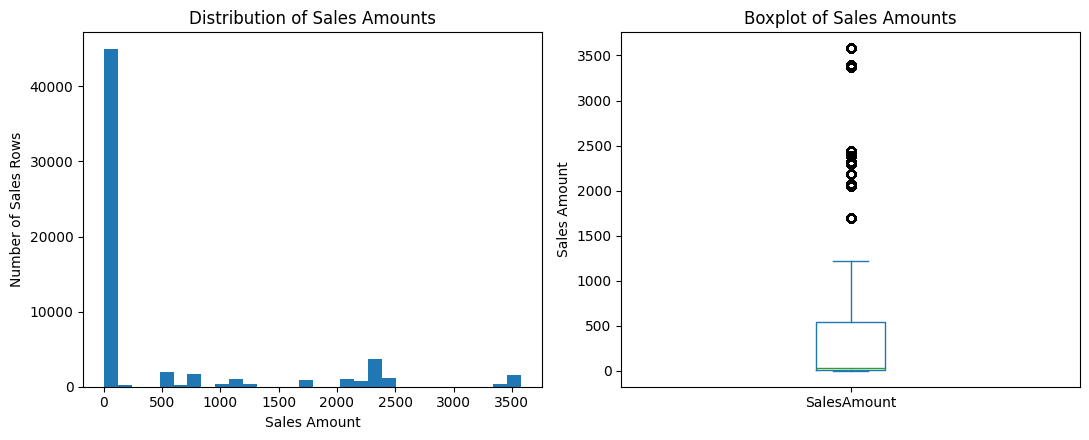

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
# Distribution of sales amounts
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

df["SalesAmount"].plot(kind="hist", bins=30, ax=axes[0])
axes[0].set_title("Distribution of Sales Amounts")
axes[0].set_xlabel("Sales Amount")
axes[0].set_ylabel("Number of Sales Rows")

df["SalesAmount"].plot(kind="box", ax=axes[1])
axes[1].set_title("Boxplot of Sales Amounts")
axes[1].set_ylabel("Sales Amount")

plt.tight_layout()
plt.savefig("sales_amount_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("sales_amount_distribution.png")


In [50]:
# Check the distributions of key customer variables

customer_profile = df.drop_duplicates(subset="CustomerKey")

print("Gender distribution:")
display(
    customer_profile["Gender"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Homeownership distribution:")
display(
    customer_profile["HomeOwnership"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Customer distribution by country region:")
display(
    customer_profile["EnglishCountryRegionName"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Yearly income distribution:")
display(
    customer_profile["YearlyIncome"]
    .describe()
    .round(2)
)

Gender distribution:


,proportion
Gender,
M,50.59
F,49.41


Homeownership distribution:


,proportion
HomeOwnership,
Homeowner,67.64
Non-homeowner,32.36


Customer distribution by country region:


,proportion
EnglishCountryRegionName,
United States,42.30
Australia,19.43
United Kingdom,10.35
France,9.79
Germany,9.63
Canada,8.50


Yearly income distribution:


,YearlyIncome
count,18484.00
mean,57305.78
std,32285.84
min,10000.00
25%,30000.00
50%,60000.00
75%,70000.00
max,170000.00


## 4. Question 1: Internet Sales by Year and Country Region


In [51]:
yearly_country_sales = df.pivot_table(
    index="OrderYear",
    columns="EnglishCountryRegionName",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
).round(2)

display(yearly_country_sales)

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
OrderYear,,,,,,
2010,20909.78,3578.27,3399.99,0.00,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


In [52]:
# Total sales by country across the full dataset
country_sales_summary = (
    df.groupby("EnglishCountryRegionName")
      .agg(
          TotalSales=("SalesAmount", "sum"),
          SalesRows=("ID", "count"),
          Customers=("CustomerKey", "nunique"),
          Orders=("SalesOrderNumber", "nunique")
      )
      .sort_values("TotalSales", ascending=False)
)

country_sales_summary["SalesSharePct"] = (
    country_sales_summary["TotalSales"] / country_sales_summary["TotalSales"].sum() * 100
)

display(country_sales_summary.round(2))

,TotalSales,SalesRows,Customers,Orders,SalesSharePct
EnglishCountryRegionName,,,,,
United States,9389789.51,21344,7819,9567,31.98
Australia,9061000.58,13345,3591,6718,30.86
United Kingdom,3391712.21,6906,1913,3031,11.55
Germany,2894312.34,5625,1780,2484,9.86
France,2644017.71,5558,1810,2484,9.01
Canada,1977844.86,7620,1571,3375,6.74


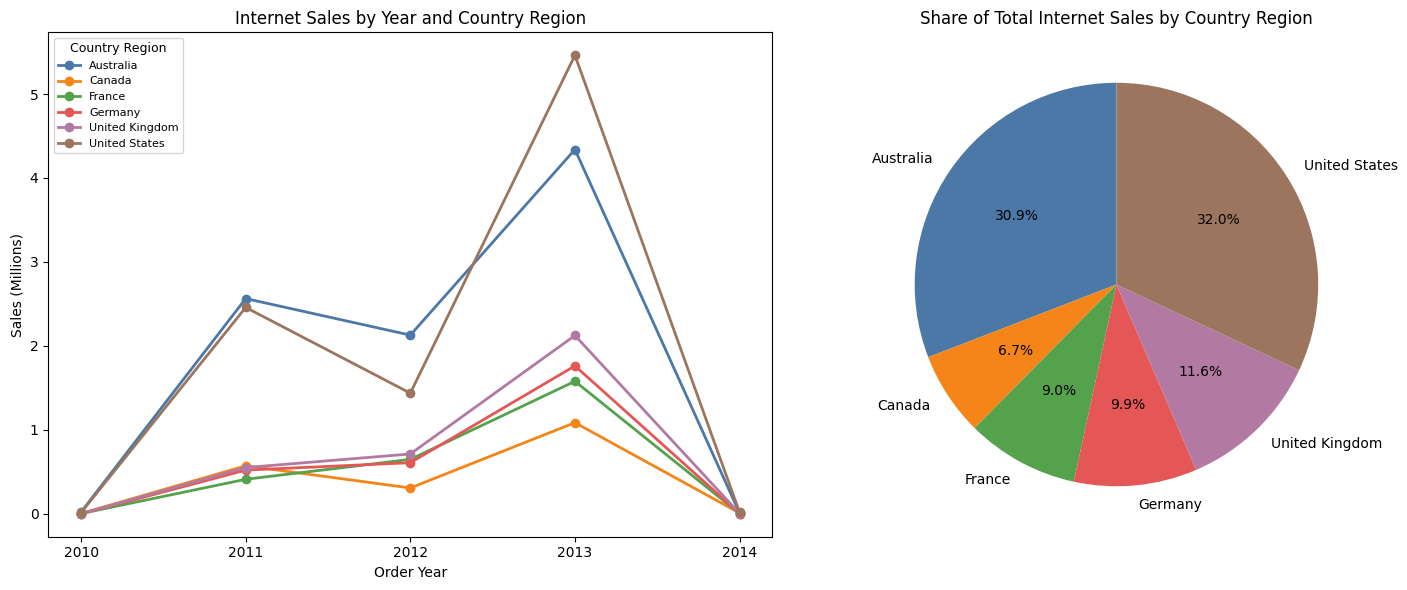

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
# Combine yearly country sales and overall country sales share
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

yearly_country_sales_millions = yearly_country_sales / 1000000

colors = ["#4C78A8", "#F58518", "#54A24B",
          "#E45756", "#B279A2", "#9C755F"]

yearly_country_sales_millions.plot(
    kind="line",
    marker="o",
    linewidth=2,
    ax=axes[0],
    color=colors
)

axes[0].set_title("Internet Sales by Year and Country Region")
axes[0].set_xlabel("Order Year")
axes[0].set_ylabel("Sales (Millions)")
axes[0].set_xticks(yearly_country_sales_millions.index)

axes[0].legend(
    title="Country Region",
    fontsize=8,
    title_fontsize=9,
    loc="upper left"
)

country_order = yearly_country_sales.columns.tolist()

overall_country_sales = (
    country_sales_summary
    .reindex(country_order)["TotalSales"]
)

overall_country_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1],
    colors=colors,
    startangle=90,
    ylabel=""
)

axes[1].set_title("Share of Total Internet Sales by Country Region")

plt.tight_layout()

plt.savefig(
    "country_sales_overview.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("country_sales_overview.png")

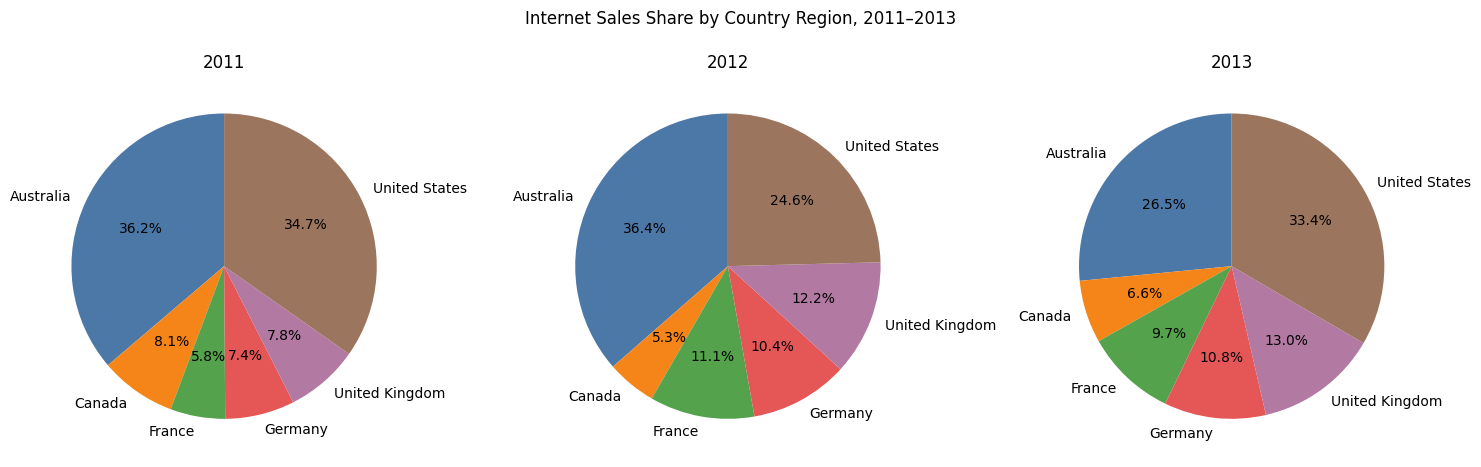

In [54]:
# Country sales share for the three complete years
full_years = [2011, 2012, 2013]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, year in enumerate(full_years):
    yearly_country_sales.loc[year].plot(
        kind="pie",
        autopct="%1.1f%%",
        colors=colors,
        startangle=90,
        ax=axes[i]
    )
    axes[i].set_title(str(year))
    axes[i].set_ylabel("")

plt.suptitle("Internet Sales Share by Country Region, 2011–2013")
plt.tight_layout()
plt.show()

### Full-year growth comparison

Because 2010 and 2014 are partial years, the growth comparison below focuses on the complete years 2011-2013.

In [55]:
full_year_sales = yearly_country_sales.loc[2011:2013]
country_growth = full_year_sales.pct_change().mul(100).round(2)
country_growth.index = ["2011", "2012", "2013"]

print("Year-over-year sales growth by country (%):")
display(country_growth)

Year-over-year sales growth by country (%):


EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
2011,NaN,NaN,NaN,NaN,NaN,NaN
2012,-16.98,-46.18,57.74,16.94,29.44,-41.54
2013,103.88,252.93,143.57,189.47,198.02,280.09


## 5. Question 2: Yearly Income and Gender by Country Region

This section creates one record per customer to avoid giving repeat customers extra weight when describing the customer population.

In [56]:
customer_profile = (
    df[[
        "CustomerKey", "EnglishCountryRegionName", "Gender",
        "YearlyIncome", "HouseOwnerFlag", "HomeOwnership"
    ]]
    .drop_duplicates(subset="CustomerKey")
    .copy()
)

print("Unique customers:", len(customer_profile))

# Confirm that customer characteristics are consistent across transaction rows
customer_unique = df.groupby("CustomerKey")[[
    "EnglishCountryRegionName", "Gender", "YearlyIncome", "HouseOwnerFlag"
]].nunique().max()

print()
print("Maximum number of distinct values per customer:")
print(customer_unique)

Unique customers: 18484

Maximum number of distinct values per customer:
EnglishCountryRegionName    1
Gender                      1
YearlyIncome                1
HouseOwnerFlag              1
dtype: int64


In [57]:
# Required descriptive statistics for Yearly Income by Gender and Country Region
income_gender_summary = (
    customer_profile
    .groupby(["EnglishCountryRegionName", "Gender"])["YearlyIncome"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

income_gender_summary.columns = [
    "N", "Mean Income", "Median Income",
    "Min Income", "Max Income", "SD Income"
]

# Calculate gender percentage within each country region
gender_percent = (
    customer_profile
    .groupby(["EnglishCountryRegionName", "Gender"])
    .size()
    .groupby(level=0)
    .transform(lambda x: x / x.sum() * 100)
    .round(2)
)

# Add gender percentage to the same summary table
income_gender_summary["Gender %"] = gender_percent

display(income_gender_summary)

N  Mean Income  Median Income  Min Income  \
EnglishCountryRegionName Gender                                                 
Australia                F       1777     65284.19        70000.0       10000   
                         M       1814     63412.35        70000.0       10000   
Canada                   F        767     56505.87        60000.0       10000   
                         M        804     57798.51        60000.0       10000   
France                   F        893     35341.55        30000.0       10000   
                         M        917     36172.30        30000.0       10000   
Germany                  F        874     43810.07        30000.0       10000   
                         M        906     42108.17        30000.0       10000   
United Kingdom           F        934     52184.15        30000.0       10000   
                         M        979     52155.26        30000.0       10000   
United States            F       3888     63276.75        60000.0       10000   
                         M       3931     63953.19        60000.0       10000   

                                 Max Income  SD Income  Gender %  
EnglishCountryRegionName Gender                                   
Australia                F           160000   31164.36     49.48  
                         M           170000   32450.71     50.52  
Canada                   F           170000   19181.55     48.82  
                         M           170000   21214.77     51.18  
France                   F           110000   26915.85     49.34  
                         M           110000   27633.45     50.66  
Germany                  F           130000   35715.76     49.10  
                         M           130000   35277.49     50.90  
United Kingdom           F           170000   48288.44     48.82  
                         M           170000   48593.22     51.18  
United States            F           170000   25166.56     49.73  
                         M           170000   26228.43     50.27

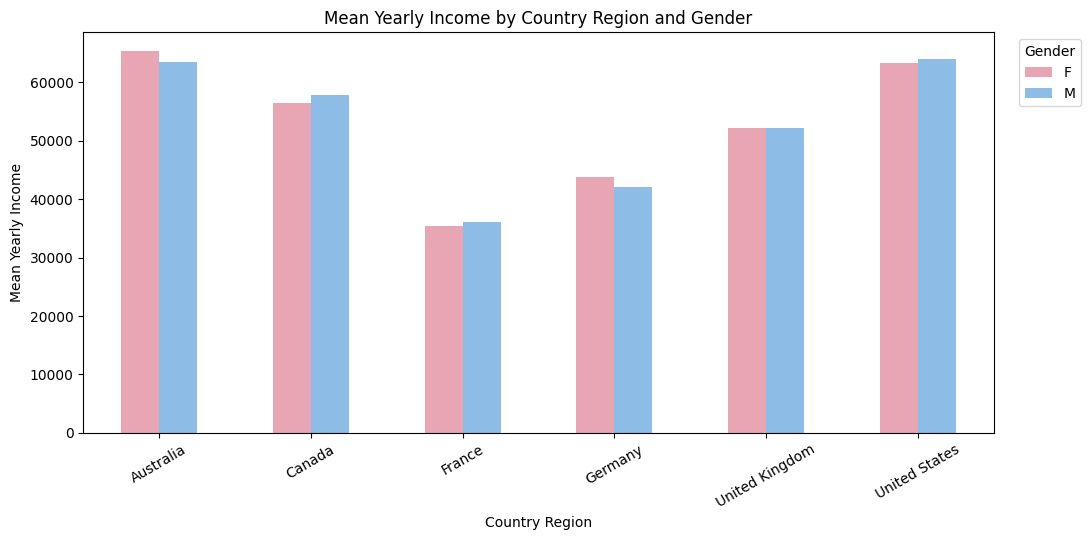

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
# Mean yearly income by country and gender
income_plot = (
    customer_profile
    .groupby(["EnglishCountryRegionName", "Gender"])["YearlyIncome"]
    .mean()
    .unstack()
)

income_plot = income_plot[["F", "M"]]

ax = income_plot.plot(
    kind="bar",
    figsize=(11, 5.5),
    color=["#E8A6B5", "#8DBCE6"]
)

ax.set_title("Mean Yearly Income by Country Region and Gender")
ax.set_xlabel("Country Region")
ax.set_ylabel("Mean Yearly Income")
ax.tick_params(axis="x", rotation=30)

ax.legend(
    title="Gender",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "mean_yearly_income_by_country_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("mean_yearly_income_by_country_gender.png")

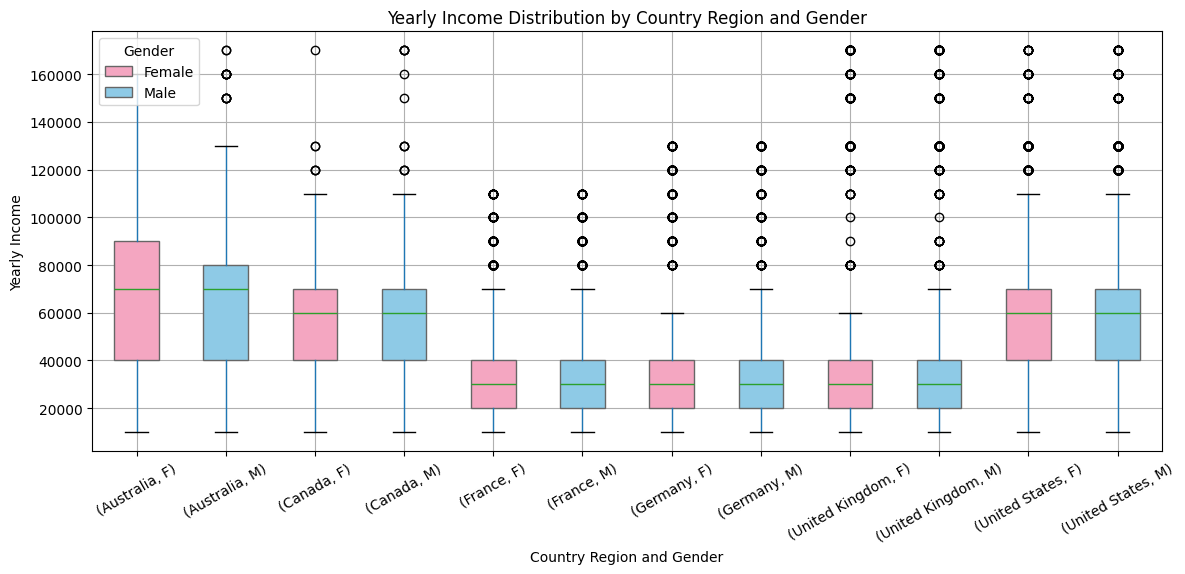

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
from matplotlib.patches import Patch

customer_profile["Gender"] = pd.Categorical(
    customer_profile["Gender"],
    categories=["F", "M"],
    ordered=True
)

ax = customer_profile.boxplot(
    column="YearlyIncome",
    by=["EnglishCountryRegionName", "Gender"],
    figsize=(12, 6),
    rot=30,
    patch_artist=True
)

female_color = "#F4A6C1"
male_color = "#8ECAE6"

for i, patch in enumerate(ax.patches):
    if i % 2 == 0:
        patch.set_facecolor(female_color)
    else:
        patch.set_facecolor(male_color)

    patch.set_edgecolor("#666666")

ax.set_title("Yearly Income Distribution by Country Region and Gender")
ax.set_xlabel("Country Region and Gender")
ax.set_ylabel("Yearly Income")

plt.suptitle("")

# Add gender legend
legend_elements = [
    Patch(facecolor=female_color, edgecolor="#666666", label="Female"),
    Patch(facecolor=male_color, edgecolor="#666666", label="Male")
]

ax.legend(
    handles=legend_elements,
    title="Gender",
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "yearly_income_distribution_by_country_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("yearly_income_distribution_by_country_gender.png")

## 6. Question 3: Product Category Sales and Average Price

The CSV contains product names but does not include a separate product-category column.

In [60]:
# Create product categories using the AdventureWorks category structure
product_names = df["EnglishProductName"]

bike_category = product_names.str.match(
    r"^(Mountain|Road|Touring)-\d",
    na=False
)

clothing_category = product_names.str.contains(
    r"Cap|Vest|Gloves|Jersey|Socks|Shorts",
    case=False,
    regex=True,
    na=False
)

accessory_category = product_names.str.contains(
    r"Stand|Wash|Fender|Tire|Tube|Bottle|Patch|Helmet|Rack|Hydration",
    case=False,
    regex=True,
    na=False
)

df["ProductCategory"] = np.select(
    [bike_category, clothing_category, accessory_category],
    ["Bikes", "Clothing", "Accessories"],
    default="Unclassified"
)

print(df["ProductCategory"].value_counts())

unclassified_products = (
    df.loc[
        df["ProductCategory"] == "Unclassified",
        "EnglishProductName"
    ]
    .drop_duplicates()
    .sort_values()
)

print("Unclassified products:")
display(unclassified_products)

ProductCategory
Accessories    36092
Bikes          15205
Clothing        9101
Name: count, dtype: int64
Unclassified products:


,EnglishProductName


In [61]:
# Summarize sales performance by product category
product_category_summary = (
    df.groupby("ProductCategory")
      .agg(
          TotalSales=("SalesAmount", "sum"),
          AveragePrice=("UnitPrice", "mean"),
          MedianPrice=("UnitPrice", "median"),
          SalesRows=("ID", "count"),
          UniqueProducts=("EnglishProductName", "nunique")
      )
      .sort_values("TotalSales", ascending=False)
)

product_category_summary["SalesSharePct"] = (
    product_category_summary["TotalSales"]
    / product_category_summary["TotalSales"].sum()
    * 100
)

display(product_category_summary.round(2))

,TotalSales,AveragePrice,MedianPrice,SalesRows,UniqueProducts,SalesSharePct
ProductCategory,,,,,,
Bikes,28318144.65,1862.42,2071.42,15205,88,96.46
Accessories,700759.96,19.42,9.99,36092,22,2.39
Clothing,339772.61,37.33,49.99,9101,20,1.16


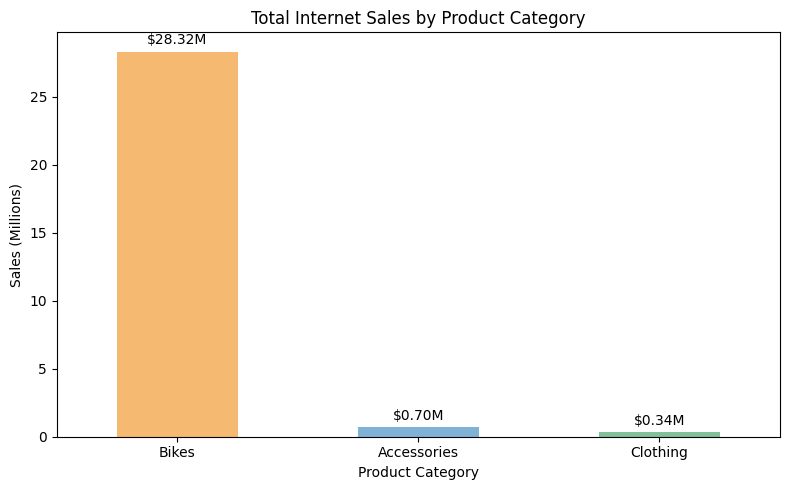

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
# Visualize category sales in millions
category_sales_millions = (
    product_category_summary["TotalSales"] / 1000000
)

ax = category_sales_millions.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#F5B971", "#7FB3D5", "#82C09A"]
)

ax.set_title("Total Internet Sales by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Sales (Millions)")
ax.tick_params(axis="x", rotation=0)

# Add value labels above each bar
for container in ax.containers:
    labels = [f"${value:.2f}M" for value in category_sales_millions]
    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    "product_category_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("product_category_sales.png")

In [63]:
# Check which product category generated the most sales in each year
year_category_sales = (
    df.groupby(["OrderYear", "ProductCategory"])["SalesAmount"]
      .sum()
      .unstack(fill_value=0)
)

display(year_category_sales.round(2))

top_category_by_year = pd.DataFrame({
    "TopCategory": year_category_sales.idxmax(axis=1),
    "TopCategorySales": year_category_sales.max(axis=1)
})

display(top_category_by_year.round(2))

ProductCategory,Accessories,Bikes,Clothing
OrderYear,,,
2010,0.00,43421.04,0.00
2011,0.00,7075525.93,0.00
2012,2147.08,5839695.33,642.79
2013,668241.53,15359502.36,323806.45
2014,30371.35,0.00,15323.37


,TopCategory,TopCategorySales
OrderYear,,
2010,Bikes,43421.04
2011,Bikes,7075525.93
2012,Bikes,5839695.33
2013,Bikes,15359502.36
2014,Accessories,30371.35


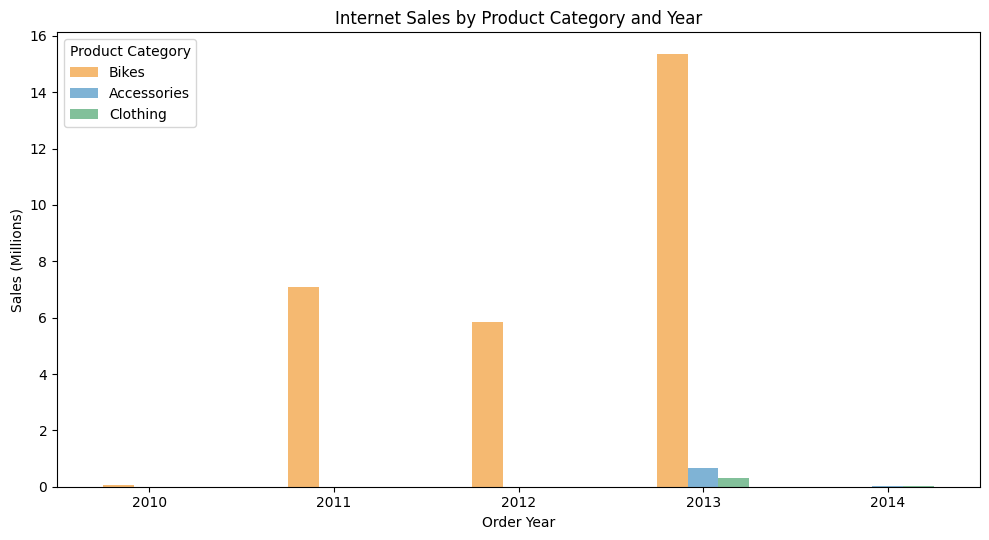

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
# Visualize product category sales by year
year_category_sales_millions = (
    year_category_sales[["Bikes", "Accessories", "Clothing"]] / 1000000
)

ax = year_category_sales_millions.plot(
    kind="bar",
    figsize=(10, 5.5),
    color=["#F5B971", "#7FB3D5", "#82C09A"]
)

ax.set_title("Internet Sales by Product Category and Year")
ax.set_xlabel("Order Year")
ax.set_ylabel("Sales (Millions)")
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Product Category",
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "product_category_sales_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("product_category_sales_by_year.png")

## 7. Question 4: Does Homeownership Make a Difference in Sales?



In [65]:
# Transaction-level business contribution by homeownership
home_sales_total = (
    df.groupby("HomeOwnership")
      .agg(
          SalesRows=("ID", "count"),
          Customers=("CustomerKey", "nunique"),
          Orders=("SalesOrderNumber", "nunique"),
          TotalSales=("SalesAmount", "sum"),
          MeanSalesRow=("SalesAmount", "mean"),
          MedianSalesRow=("SalesAmount", "median")
      )
)

home_sales_total["SalesSharePct"] = (
    home_sales_total["TotalSales"] / home_sales_total["TotalSales"].sum() * 100
)

display(home_sales_total.round(2))

,SalesRows,Customers,Orders,TotalSales,MeanSalesRow,MedianSalesRow,SalesSharePct
HomeOwnership,,,,,,,
Homeowner,41699,12502,19058,20385349.80,488.87,32.60,69.44
Non-homeowner,18699,5982,8601,8973327.42,479.88,29.99,30.56


In [66]:
# Aggregate transaction rows to one row per customer
customer_sales = (
    df.groupby(["CustomerKey", "HomeOwnership"])
      .agg(
          TotalCustomerSales=("SalesAmount", "sum"),
          Orders=("SalesOrderNumber", "nunique"),
          SalesRows=("ID", "count")
      )
      .reset_index()
)

customer_sales["RepeatCustomer"] = customer_sales["Orders"] > 1
customer_sales.head()

,CustomerKey,HomeOwnership,TotalCustomerSales,Orders,SalesRows,RepeatCustomer
0,11000,Homeowner,8248.99,3,8,True
1,11001,Non-homeowner,6383.88,3,11,True
2,11002,Homeowner,8114.04,3,4,True
3,11003,Non-homeowner,8139.29,3,9,True
4,11004,Homeowner,8196.01,3,6,True


In [67]:
# Compare customer-level sales behavior by homeownership
home_customer_summary = (
    customer_sales.groupby("HomeOwnership")
    .agg(
        Customers=("CustomerKey", "count"),
        MeanSalesPerCustomer=("TotalCustomerSales", "mean"),
        MedianSalesPerCustomer=("TotalCustomerSales", "median"),
        SDSalesPerCustomer=("TotalCustomerSales", "std"),
        MeanOrdersPerCustomer=("Orders", "mean"),
        RepeatCustomerRate=("RepeatCustomer", "mean")
    )
)

home_customer_summary["RepeatCustomerRatePct"] = (
    home_customer_summary["RepeatCustomerRate"] * 100
)

home_customer_summary = home_customer_summary.drop(columns="RepeatCustomerRate")
display(home_customer_summary.round(2))

,Customers,MeanSalesPerCustomer,MedianSalesPerCustomer,SDSalesPerCustomer,MeanOrdersPerCustomer,RepeatCustomerRatePct
HomeOwnership,,,,,,
Homeowner,12502,1630.57,342.00,2159.07,1.52,38.58
Non-homeowner,5982,1500.05,209.96,2046.88,1.44,34.14


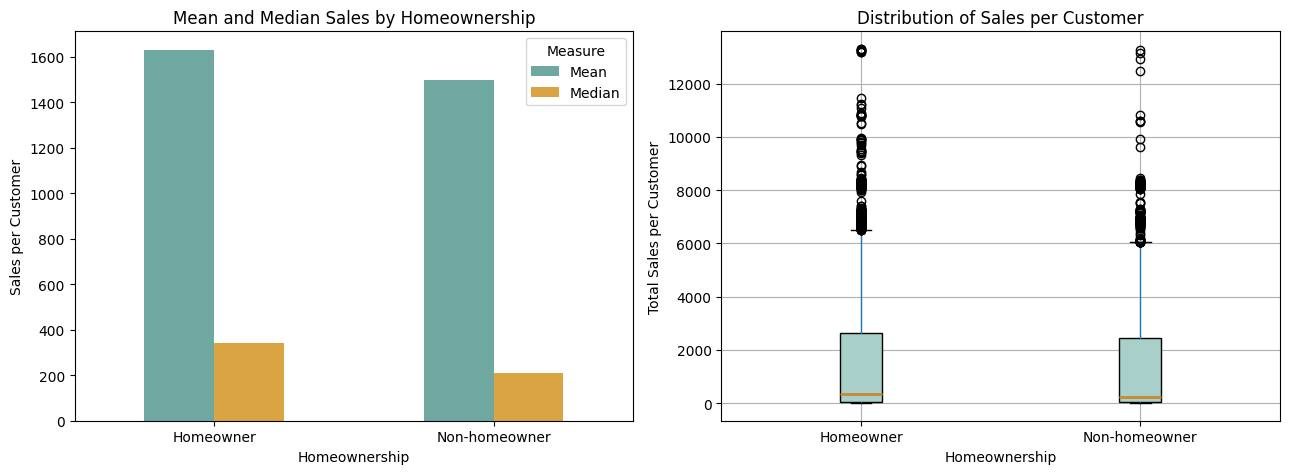

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
# Compare mean and median sales and customer-level sales distribution by homeownership
home_customer_plot = home_customer_summary[[
    "MeanSalesPerCustomer", "MedianSalesPerCustomer"
]]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mean and median sales per customer
home_customer_plot.plot(
    kind="bar",
    ax=axes[0],
    color=["#6FA8A1", "#D9A441"]
)

axes[0].set_title("Mean and Median Sales by Homeownership")
axes[0].set_xlabel("Homeownership")
axes[0].set_ylabel("Sales per Customer")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(["Mean", "Median"], title="Measure")

# Distribution of total sales per customer
customer_sales.boxplot(
    column="TotalCustomerSales",
    by="HomeOwnership",
    ax=axes[1],
    patch_artist=True,
    boxprops=dict(facecolor="#A8CFC9"),
    medianprops=dict(color="#C78B2C", linewidth=2)
)

axes[1].set_title("Distribution of Sales per Customer")
axes[1].set_xlabel("Homeownership")
axes[1].set_ylabel("Total Sales per Customer")

plt.suptitle("")
plt.tight_layout()

plt.savefig(
    "sales_by_homeownership.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("sales_by_homeownership.png")

## 8. Additional Analysis: Product Mix by Country Region

Leadership's growth decision depends not only on which countries generate sales and which category is largest overall, but also on whether product demand differs across markets. This table combines the geographic and product analyses.

In [69]:
country_category_sales = df.pivot_table(
    index="EnglishCountryRegionName",
    columns="ProductCategory",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
).round(2)

display(country_category_sales)

ProductCategory,Accessories,Bikes,Clothing
EnglishCountryRegionName,,,
Australia,138690.63,8852050.00,70259.95
Canada,103377.85,1821302.39,53164.62
France,63406.78,2553575.71,27035.22
Germany,62232.59,2808514.35,23565.40
United Kingdom,76630.04,3282842.66,32239.51
United States,256422.07,8999859.53,133507.91


In [70]:
# Convert category sales to a within-country percentage mix
country_category_share = (
    country_category_sales
    .div(country_category_sales.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Product category share of each country's Internet sales (%):")
display(country_category_share)

Product category share of each country's Internet sales (%):


ProductCategory,Accessories,Bikes,Clothing
EnglishCountryRegionName,,,
Australia,1.53,97.69,0.78
Canada,5.23,92.09,2.69
France,2.40,96.58,1.02
Germany,2.15,97.04,0.81
United Kingdom,2.26,96.79,0.95
United States,2.73,95.85,1.42


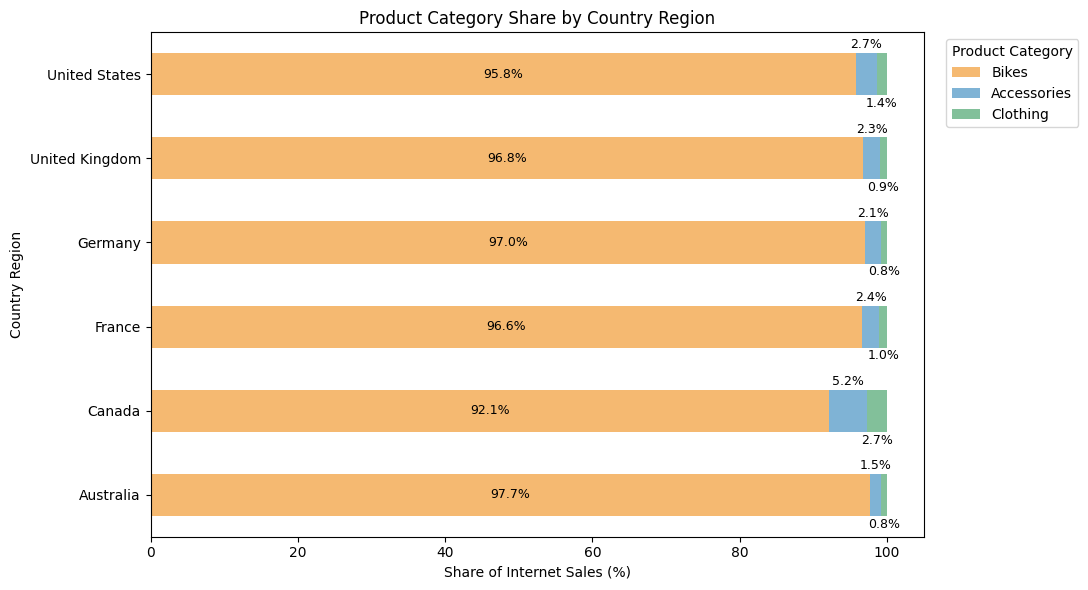

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
# Reorder product categories
category_order = ["Bikes", "Accessories", "Clothing"]
country_category_share = country_category_share[category_order]

ax = country_category_share.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=["#F5B971", "#7FB3D5", "#82C09A"]
)

ax.set_title("Product Category Share by Country Region")
ax.set_xlabel("Share of Internet Sales (%)")
ax.set_ylabel("Country Region")

ax.legend(
    title="Product Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


for bar, value in zip(ax.containers[0], country_category_share["Bikes"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        ha="center",
        va="center",
        fontsize=9
    )
for bar, value in zip(ax.containers[1], country_category_share["Accessories"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_y() + bar.get_height() / 2 + 0.35,
        f"{value:.1f}%",
        ha="center",
        va="center",
        fontsize=9
    )
for bar, value in zip(ax.containers[2], country_category_share["Clothing"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_y() + bar.get_height() / 2 - 0.35,
        f"{value:.1f}%",
        ha="center",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "product_category_share_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("product_category_share_by_country.png")

## 9. Additional Analysis: Customer Value and Repeat Purchasing

Growth can come from acquiring more customers or increasing the value of existing customers. The following summary compares customer value and repeat purchasing across country regions.

In [72]:
# Add country information to the customer-level sales table
customer_country = customer_profile[["CustomerKey", "EnglishCountryRegionName"]]
customer_value = customer_sales.merge(customer_country, on="CustomerKey", how="left")

customer_value_summary = (
    customer_value.groupby("EnglishCountryRegionName")
    .agg(
        Customers=("CustomerKey", "count"),
        MeanSalesPerCustomer=("TotalCustomerSales", "mean"),
        MedianSalesPerCustomer=("TotalCustomerSales", "median"),
        MeanOrdersPerCustomer=("Orders", "mean"),
        RepeatCustomerRate=("RepeatCustomer", "mean")
    )
    .sort_values("MeanSalesPerCustomer", ascending=False)
)

customer_value_summary["RepeatCustomerRatePct"] = (
    customer_value_summary["RepeatCustomerRate"] * 100
)
customer_value_summary = customer_value_summary.drop(columns="RepeatCustomerRate")

display(customer_value_summary.round(2))

,Customers,MeanSalesPerCustomer,MedianSalesPerCustomer,MeanOrdersPerCustomer,RepeatCustomerRatePct
EnglishCountryRegionName,,,,,
Australia,3591,2523.25,1938.47,1.87,71.87
United Kingdom,1913,1772.98,565.47,1.58,45.06
Germany,1780,1626.02,539.99,1.40,28.15
France,1810,1460.78,97.71,1.37,25.30
Canada,1571,1258.97,232.71,2.15,46.15
United States,7819,1200.89,123.98,1.22,22.23


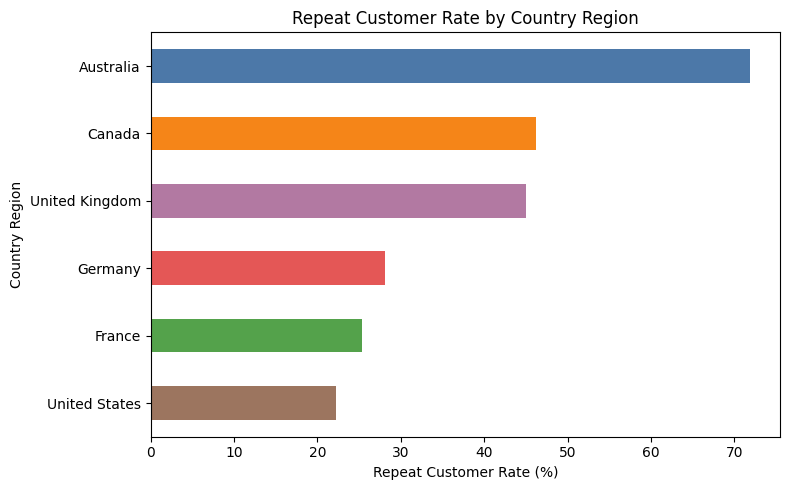

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
country_colors = {
    "Australia": "#4C78A8",
    "Canada": "#F58518",
    "France": "#54A24B",
    "Germany": "#E45756",
    "United Kingdom": "#B279A2",
    "United States": "#9C755F"
}

repeat_rate = customer_value_summary["RepeatCustomerRatePct"].sort_values()

ax = repeat_rate.plot(
    kind="barh",
    figsize=(8, 5),
    color=[country_colors[country] for country in repeat_rate.index]
)

ax.set_title("Repeat Customer Rate by Country Region")
ax.set_xlabel("Repeat Customer Rate (%)")
ax.set_ylabel("Country Region")

plt.tight_layout()

plt.savefig(
    "repeat_customer_rate_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files
files.download("repeat_customer_rate_by_country.png")

## 10. Summary of Findings


In [74]:
# Main business findings generated from the analysis
largest_country = country_sales_summary.index[0]
largest_country_sales = country_sales_summary.iloc[0]["TotalSales"]

top_category = product_category_summary.index[0]
top_category_average_price = product_category_summary.iloc[0]["AveragePrice"]

homeowner_mean = home_customer_summary.loc["Homeowner", "MeanSalesPerCustomer"]
nonhomeowner_mean = home_customer_summary.loc["Non-homeowner", "MeanSalesPerCustomer"]
homeowner_difference = homeowner_mean - nonhomeowner_mean

print("1. Largest country market overall:", largest_country,
      "with ${:,.2f} in Internet sales.".format(largest_country_sales))

print("2. Top product category:", top_category,
      "with an average price of ${:,.2f}.".format(top_category_average_price))

print("3. Average customer sales difference for homeowners versus non-homeowners: ${:,.2f}.".format(
    homeowner_difference
))

sales_2011 = yearly_country_sales.loc[2011].sum()
sales_2012 = yearly_country_sales.loc[2012].sum()
sales_2013 = yearly_country_sales.loc[2013].sum()

change_2011_2012 = (sales_2012 - sales_2011) / sales_2011 * 100
change_2012_2013 = (sales_2013 - sales_2012) / sales_2012 * 100

print(
    "4. Total Internet sales changed from ${:,.2f} in 2011 to ${:,.2f} in 2012 ({:+.1f}%), "
    "then increased to ${:,.2f} in 2013 ({:+.1f}%).".format(
        sales_2011,
        sales_2012,
        change_2011_2012,
        sales_2013,
        change_2012_2013
    )
)


1. Largest country market overall: United States with $9,389,789.51 in Internet sales.
2. Top product category: Bikes with an average price of $1,862.42.
3. Average customer sales difference for homeowners versus non-homeowners: $130.51.
4. Total Internet sales changed from $7,075,525.93 in 2011 to $5,842,485.19 in 2012 (-17.4%), then increased to $16,351,550.34 in 2013 (+179.9%).
